# APP

In [1]:
from PIL import Image
import numpy as np
from pathlib import Path
from epb_detection_system import preprocess_epb_image, EPBRecognitionSystem, TwoDPCA, EPBModelData, load_model

In [2]:
EXPECTED_MODEL_VERSION = '2.0'

# 1. Carrega o modelo (com verificação de integridade SHA-256)
print("📦 Carregando modelo treinado...")
model_data = load_model('models/epb_recognition_model-v2.0.pkl')

# Verifica versão do modelo
if model_data.version != EXPECTED_MODEL_VERSION:
    print(f"   ⚠️  AVISO: Versão do modelo ({model_data.version}) difere da esperada ({EXPECTED_MODEL_VERSION}).")
    print(f"         O modelo pode ser incompatível. Considere re-treinar.")
else:
    print(f"   ✓ Versão do modelo: v{model_data.version}")

system = model_data.system
target_size = model_data.target_size

print("   ✓ Modelo carregado com sucesso!")
print()

# 2. Processa todas as imagens do diretório img-teste
img_folder = Path('img-teste')
image_files = sorted(list(img_folder.glob('*.png')) + list(img_folder.glob('*.jpg')) + list(img_folder.glob('*.jpeg')))

if len(image_files) == 0:
    print("⚠️  Nenhuma imagem encontrada no diretório 'img-teste'")
else:
    print("="*70)
    print(f"🔍 PREDIÇÕES PARA {len(image_files)} IMAGENS")
    print("="*70 + "\n")
    
    for img_path in image_files:
        try:
            # Carrega e processa imagem
            img = Image.open(img_path).convert('L')
            img = np.array(img.resize(target_size))
            
            # Pré-processamento simplificado
            img = preprocess_epb_image(img)
            
            # Faz predição (uma só chamada)
            prob = system.predict_proba(img.reshape(1, *img.shape))[0]
            pred = np.argmax(prob)
            
            # Exibe resultado
            print(f"📸 {img_path.name}")
            print(f"   EPB detectada: {'SIM' if pred == 1 else 'NÃO'}")
            print(f"   Probabilidade: {prob[1]*100:.2f}%")
            
            # Indicador de confiança
            confidence = max(prob)
            if confidence > 0.9:
                print(f"   Confiança: 🟢 ALTA ({confidence*100:.1f}%)")
            elif confidence > 0.7:
                print(f"   Confiança: 🟡 MÉDIA ({confidence*100:.1f}%)")
            else:
                print(f"   Confiança: 🔴 BAIXA ({confidence*100:.1f}%)")
            print()
            
        except Exception as e:
            print(f"❌ {img_path.name}")
            print(f"   Erro ao processar: {str(e)}")
            print()
    
    print("="*70)
    print("✅ PROCESSAMENTO CONCLUÍDO")
    print("="*70)

📦 Carregando modelo treinado...
   ✓ Versão do modelo: v2.0
   ✓ Modelo carregado com sucesso!

🔍 PREDIÇÕES PARA 2 IMAGENS

📸 O6_BJL_20250723_003008.png
   EPB detectada: NÃO
   Probabilidade: 0.36%
   Confiança: 🟢 ALTA (99.6%)

📸 O6_CA_20251023_001620.png
   EPB detectada: SIM
   Probabilidade: 99.55%
   Confiança: 🟢 ALTA (99.5%)

✅ PROCESSAMENTO CONCLUÍDO


🔬 ANÁLISE DETALHADA DE FEATURES PARA 2 IMAGENS



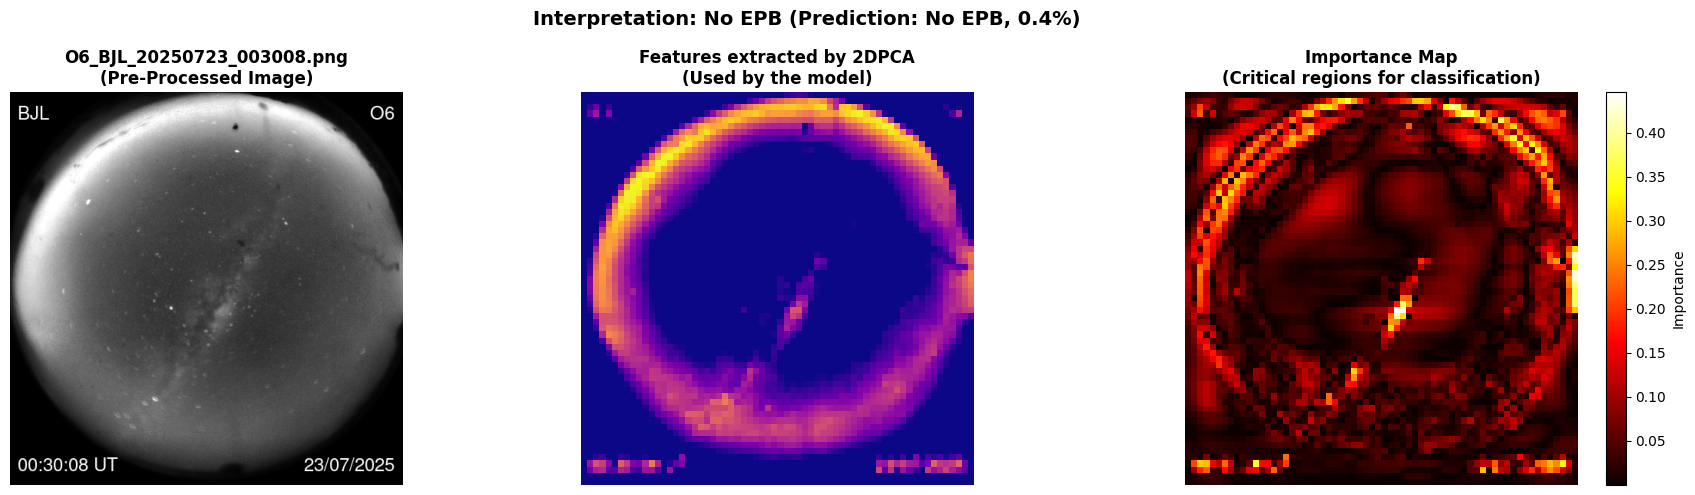

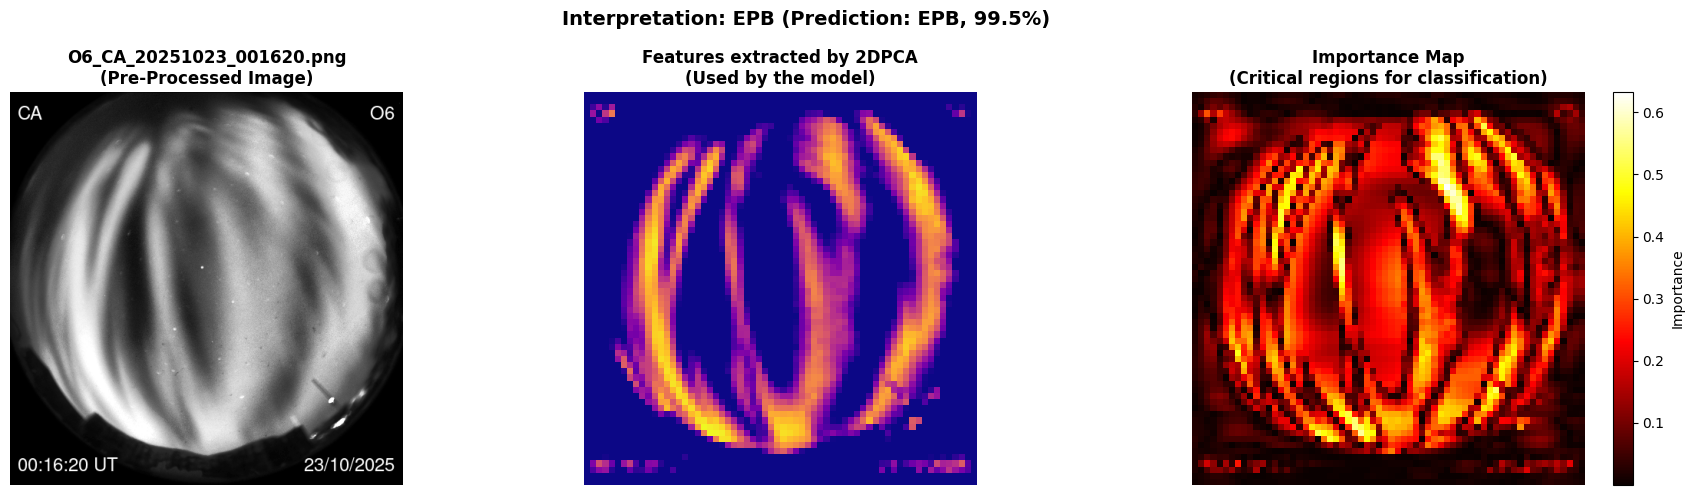

In [3]:
from epb_detection_system import explain_feature_importance_3 as efi

# Processa todas as imagens do diretório img-teste para análise detalhada
img_folder = Path('img-teste')
image_files = sorted(list(img_folder.glob('*.png')) + list(img_folder.glob('*.jpg')) + list(img_folder.glob('*.jpeg')))

if len(image_files) == 0:
    print("⚠️  Nenhuma imagem encontrada no diretório 'img-teste'")
else:
    print("="*70)
    print(f"🔬 ANÁLISE DETALHADA DE FEATURES PARA {len(image_files)} IMAGENS")
    print("="*70 + "\n")
    
    for img_path in image_files:
        try:
            # Carrega e processa imagem
            img = Image.open(img_path).convert('L')
            img_original = np.array(img.resize(target_size))
            img_processed = preprocess_epb_image(img_original.copy())
            
            # Faz predição para obter o label predito
            pred = system.predict(img_processed.reshape(1, *img_processed.shape))[0]
            
            # Chama explain_feature_importance
            # Usa pred como y_sample (classe predita) para análise
            importance_map = efi(
                system=system,
                X_sample=img_processed,
                y_sample=pred,  # Usa predição como "classe real" para análise
                filename=img_path.name
            )
        except Exception as e:
            print(f"\n❌ Erro ao analisar {img_path.name}:")
            print(f"   {str(e)}")
            import traceback
            traceback.print_exc()
            print()

📦 Carregando imagens de background para análise SHAP...


/home/ivo/miniconda3/envs/mestrado/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
TreeExplainer falhou com xgboost, tentando próximo modelo...


   ✓ 100 imagens de background carregadas

🔬 ANÁLISE SHAP PARA 2 IMAGENS


🔬 ANÁLISE SHAP — Importance Real para Classificação

📸 Imagem: O6_BJL_20250723_003008.png
   • True class: No EPB
   • Prediction: No EPB (0.4%)
   • Método SHAP: TreeExplainer (tree-based)

📊 SHAP contribution by quadrant:
   • Upper Left: 47.1% (↑ EPB)
   • Upper Right: 43.5% (↑ EPB)
   • Lower Left: 4.8% (↑ EPB)
   • Lower Right: 4.6% (↑ EPB)

📐 Correlação |SHAP| vs. Reconstruction Error: 0.154 (Spearman)
   → Baixa correlação: SHAP e reconstrução focam em regiões distintas

💡 Interpretation:
   As regiões azuis no mapa SHAP mostram evidência de ionosfera
   quieta (ausência de estruturas irregulares).


/home/ivo/Documentos/Mestrado/dissertação/code/epb_detection_system.py:2744: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/ivo/Documentos/Mestrado/dissertação/code/epb_detection_system.py:2744: UserWarning: Glyph 128309 (\N{LARGE BLUE CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/ivo/miniconda3/envs/mestrado/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/ivo/miniconda3/envs/mestrado/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128309 (\N{LARGE BLUE CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


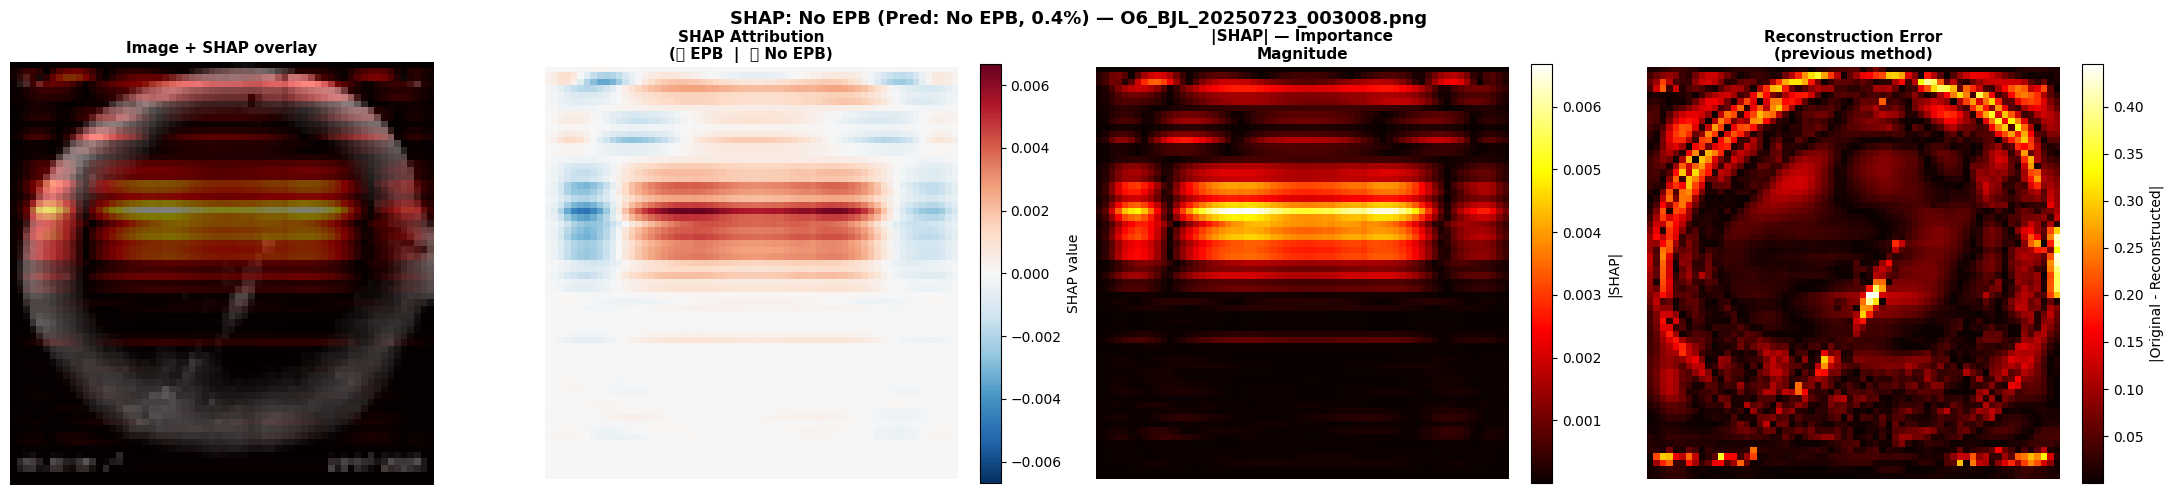

TreeExplainer falhou com xgboost, tentando próximo modelo...
/home/ivo/Documentos/Mestrado/dissertação/code/epb_detection_system.py:2744: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/ivo/Documentos/Mestrado/dissertação/code/epb_detection_system.py:2744: UserWarning: Glyph 128309 (\N{LARGE BLUE CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/ivo/miniconda3/envs/mestrado/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/ivo/miniconda3/envs/mestrado/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128309 (\N{LARGE BLUE CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)



🔬 ANÁLISE SHAP — Importance Real para Classificação

📸 Imagem: O6_CA_20251023_001620.png
   • True class: EPB
   • Prediction: EPB (99.5%)
   • Método SHAP: TreeExplainer (tree-based)

📊 SHAP contribution by quadrant:
   • Upper Left: 45.1% (↓ No EPB)
   • Upper Right: 42.5% (↓ No EPB)
   • Lower Left: 6.4% (↓ No EPB)
   • Lower Right: 6.0% (↓ No EPB)

📐 Correlação |SHAP| vs. Reconstruction Error: 0.185 (Spearman)
   → Baixa correlação: SHAP e reconstrução focam em regiões distintas

💡 Interpretation:
   As regiões vermelhas no mapa SHAP mostram onde o modelo
   encontra evidência de EPB (estruturas verticais, deplecções).


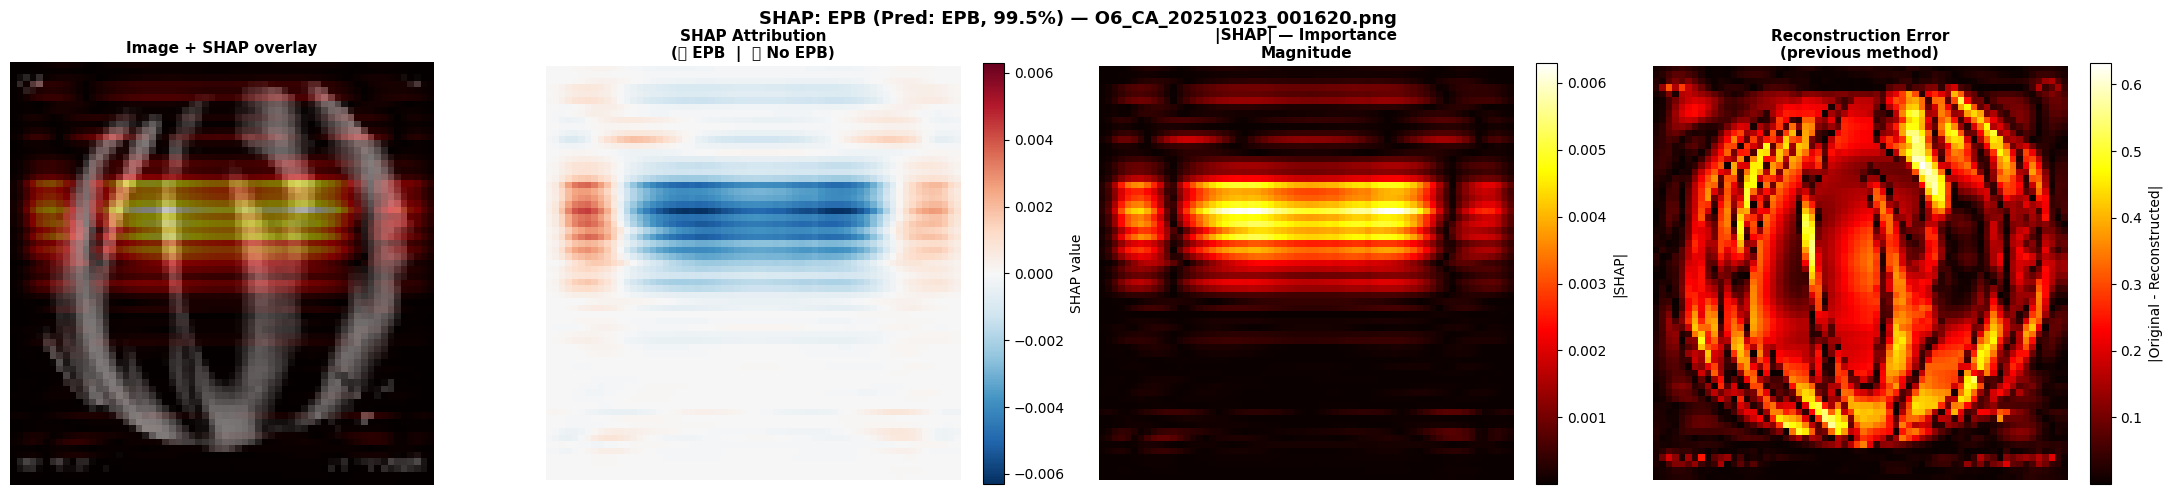

In [4]:
from epb_detection_system import explain_shap_importance, load_epb_dataset

# Carrega subconjunto de imagens como background para SHAP
print("📦 Carregando imagens de background para análise SHAP...")
X_bg, _, _ = load_epb_dataset(
    data_folder='data/all-images',
    label_file='data/epb_labels.csv',
    target_size=target_size,
    apply_preprocessing=True
)
# Subsample para eficiência
if len(X_bg) > 100:
    bg_idx = np.random.RandomState(42).choice(len(X_bg), 100, replace=False)
    X_bg = X_bg[bg_idx]
print(f"   ✓ {len(X_bg)} imagens de background carregadas\n")

# Analisa imagens com SHAP
img_folder = Path('img-teste')
image_files = sorted(list(img_folder.glob('*.png')) + list(img_folder.glob('*.jpg')) + list(img_folder.glob('*.jpeg')))

if len(image_files) == 0:
    print("⚠️  Nenhuma imagem encontrada no diretório 'img-teste'")
else:
    print("="*70)
    print(f"🔬 ANÁLISE SHAP PARA {len(image_files)} IMAGENS")
    print("="*70 + "\n")
    
    for img_path in image_files:
        try:
            img = Image.open(img_path).convert('L')
            img_original = np.array(img.resize(target_size))
            img_processed = preprocess_epb_image(img_original.copy())
            
            pred = system.predict(img_processed.reshape(1, *img_processed.shape))[0]
            
            explain_shap_importance(
                system=system,
                X_sample=img_processed,
                y_sample=pred,
                X_background=X_bg,
                filename=img_path.name,
                method='tree',
            )
        except Exception as e:
            print(f"\n❌ Erro ao analisar {img_path.name}: {str(e)}")
            import traceback
            traceback.print_exc()
            print()

## 🕐 Análise Temporal de Sequência de Imagens

Analisa como a probabilidade de EPB evolui ao longo de uma noite de observação.
Útil para verificar se o modelo detecta EPBs **antes** de serem visíveis ao olho humano.

📂 Pastas disponíveis para análise temporal:
   0: util/BJL_20250722/processed  (230 imagens)
   1: util/CA_20250407/processed  (57 imagens)
   2: util/CA_20251022/processed  (140 imagens)
   3: util/CA_20251027/processed  (103 imagens)
   4: util/CA_20251218/processed  (136 imagens)
   5: util/CP_20240209/processed  (123 imagens)
   6: util/STR_20231112/processed  (135 imagens)

🔍 Selecionada: util/CA_20251022/processed

🕐 TEMPORAL SEQUENCE ANALYSIS OF IMAGES
📂 Folder: util/CA_20251022/processed
📸 Total images: 140

📊 Prediction summary:
   • With EPB: 140 images (100.0%)
   • No EPB: 0 images (0.0%)
   • Average EPB probability: 95.4%
   • Maximum EPB probability: 99.5%
   • Minimum EPB probability: 61.5%


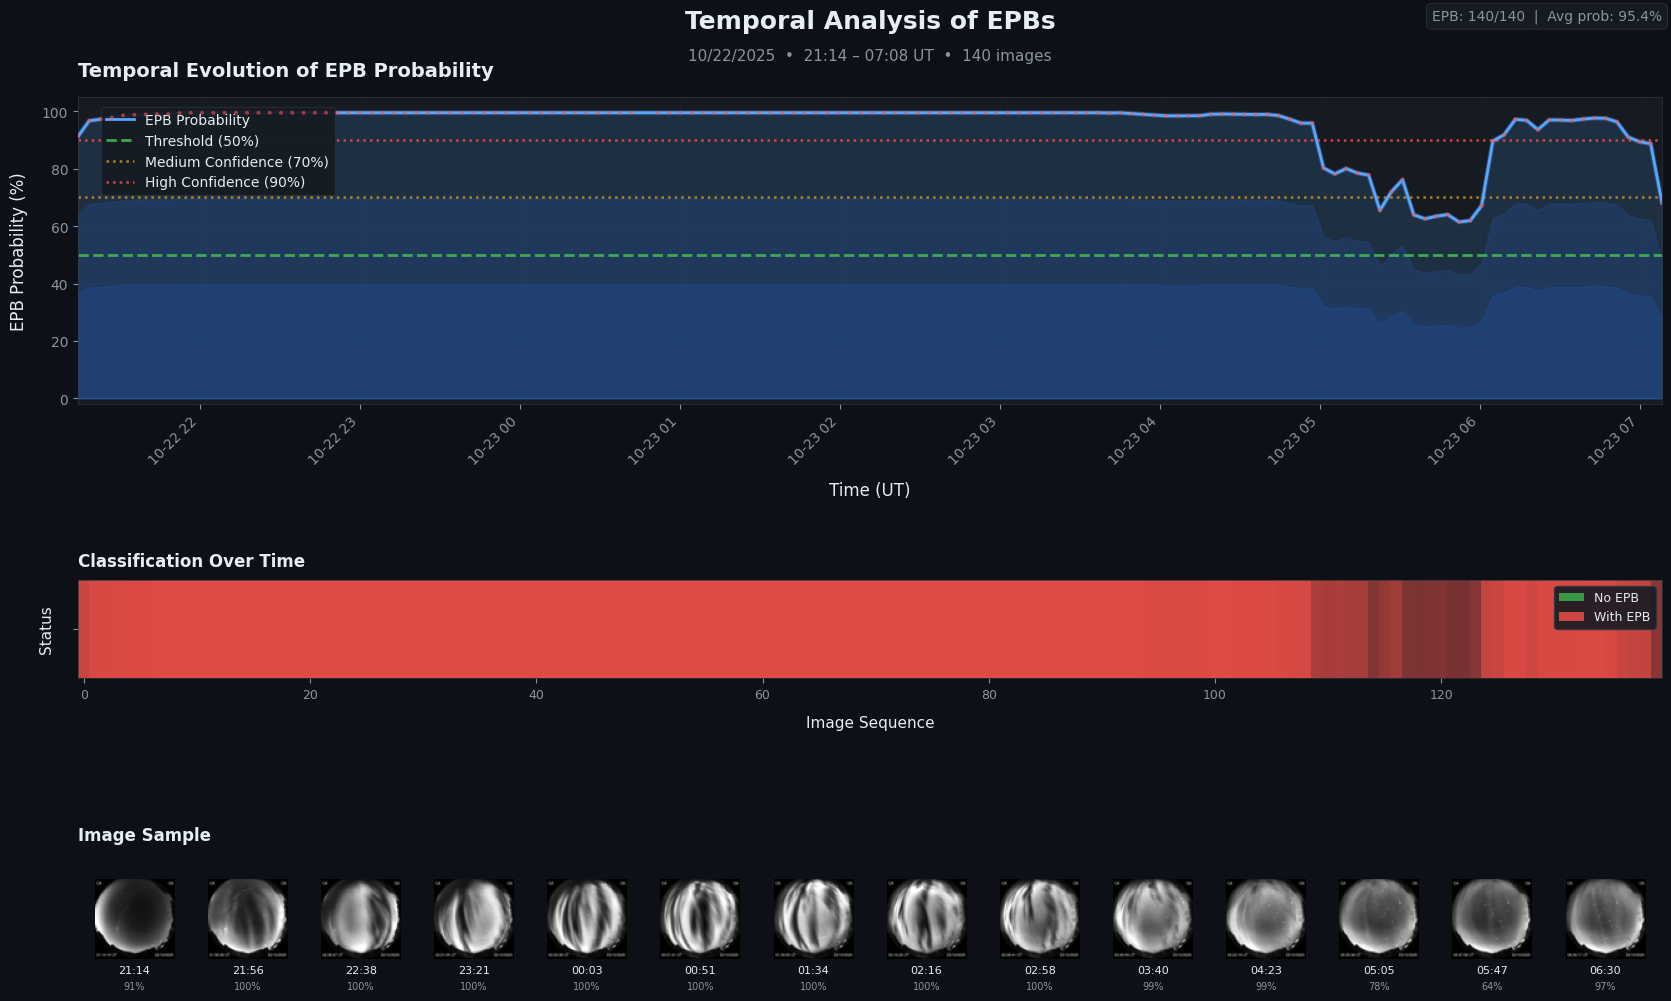


✅ TEMPORAL ANALYSIS COMPLETED


In [5]:
from epb_detection_system import analyze_temporal_sequence

# Lista automaticamente as pastas disponíveis em util/*/processed
available_folders = sorted(Path('util').glob('*/processed'))

print("📂 Pastas disponíveis para análise temporal:")
for i, folder in enumerate(available_folders):
    n_imgs = len(list(folder.glob('*.png')))
    print(f"   {i}: {folder}  ({n_imgs} imagens)")

# Seleciona a pasta desejada (altere o índice conforme necessário)
FOLDER_INDEX = 2
IMAGE_FOLDER = str(available_folders[FOLDER_INDEX])
print(f"\n🔍 Selecionada: {IMAGE_FOLDER}\n")

# Executa análise temporal
df_temporal = analyze_temporal_sequence(
    system=system,
    image_folder=IMAGE_FOLDER,
    target_size=target_size,
    show_thumbnails=True,
    thumbnail_interval=10  # Mostra thumbnail a cada 10 imagens
)

In [6]:
from epb_detection_system import analyze_critical_periods

analyze_critical_periods(df_temporal)

🔍 CRITICAL PERIODS ANALYSIS
📅 Date: 10/22/2025 | Period: 21:14 - 07:08 UT

📈 OVERALL NIGHT STATISTICS
----------------------------------------------------------------------
   • Total images: 140
   • With EPB detected: 140 (100.0%)
   • No EPB detected: 0 (0.0%)
   • Number of transitions: 0

   • Average EPB probability: 95.4%
   • Maximum probability: 99.5%
   • Minimum probability: 61.5%

   🎯 Activity peak: 23:08:24 UT (99.5%)

✅ ANALYSIS COMPLETED
